# 04 Exploration des variables

Les 30 variables de `data/features.parquet` (notebook 03), avant la modélisation. On regarde la population, les distributions, les redondances et la dérive d'une cohorte à l'autre. Les seuils sont pris sur l'entraînement (T0 = 2014 à 2018). Pour la cohorte de test (T0 = 2021), on ne regarde que les variables, jamais y.

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append("..")
from src.modelisation import auc
from src.nettoyage import lire

table = pd.read_parquet("../data/features.parquet")
variables = table.columns.drop(["artist", "t0", "y"])
numeriques = table[variables].select_dtypes(["number", "bool"]).columns
table[numeriques] = table[numeriques].astype(float)
table = table.join(lire("artist", ["id", "gid", "name"]).set_index("id"), on="artist")
entrainement = table[table["t0"] < 2021]
print(f"{len(table)} lignes, {len(variables)} variables")

340179 lignes, 30 variables


## 1. Population

In [2]:
types = pd.crosstab(table["t0"], table["type"].fillna("manquant"), normalize="index").mul(100).round(1)
types.insert(0, "artistes", table.groupby("t0").size())
types.insert(1, "% de positifs", (100 * entrainement.groupby("t0")["y"].mean()).round(2))
types

type,artistes,% de positifs,Character,Choir,Group,Orchestra,Other,Person,manquant
t0,,,,,,,,,
2014,41081,1.15,0.4,0.1,56.7,0.0,0.2,35.5,7.1
2015,47075,1.10,0.5,0.1,58.1,0.1,0.2,34.7,6.4
2016,51359,1.03,0.6,0.1,56.5,0.1,0.2,35.2,7.3
2017,56812,1.03,0.6,0.1,53.7,0.2,0.1,36.1,9.2
2018,61480,1.01,0.6,0.1,49.9,0.2,0.1,38.4,10.7
2021,82372,NaN,0.5,0.1,45.0,0.1,0.2,43.9,10.3


In [3]:
pays = table["pays"].fillna("manquant")
principaux = list(pays.value_counts().index[:8])
pd.crosstab(table["t0"], pays.where(pays.isin(principaux), "autres"), normalize="index").mul(100).round(1)[principaux + ["autres"]]

pays,US,manquant,GB,DE,FR,JP,CA,IT,autres
t0,,,,,,,,,
2014,22.0,18.4,11.3,5.2,4.1,3.1,4.3,2.4,29.2
2015,21.0,19.5,11.1,4.9,4.3,5.1,4.0,2.3,27.7
2016,20.7,21.2,10.9,5.0,5.1,5.0,3.4,2.3,26.4
2017,22.2,20.2,11.0,5.3,5.5,4.1,3.3,2.3,26.0
2018,22.6,19.5,11.3,5.4,5.5,3.9,3.3,2.2,26.4
2021,23.0,19.9,10.5,5.4,4.8,3.5,3.3,2.0,27.6


In [4]:
disques = table["albums"] + table["eps"] + table["singles"]
tranches = pd.cut(disques, [0, 1, 2, 3, 5, 10, np.inf], labels=["1", "2", "3", "4 à 5", "6 à 10", "plus de 10"])
activite = pd.crosstab(table["t0"], tranches.rename("disques sur 3 ans"), normalize="index").mul(100).round(1)
activite["sans label connu"] = (100 * (table["part_label_connu"] == 0).groupby(table["t0"]).mean()).round(1)
activite

disques sur 3 ans,1,2,3,4 à 5,6 à 10,plus de 10,sans label connu
t0,,,,,,,
2014,77.2,14.0,4.6,2.8,1.2,0.2,37.0
2015,76.5,14.5,4.6,2.9,1.3,0.2,41.9
2016,75.7,14.8,4.9,3.1,1.3,0.2,43.3
2017,74.8,15.2,5.1,3.3,1.3,0.3,42.5
2018,73.6,15.5,5.5,3.5,1.6,0.4,42.3
2021,67.1,16.1,6.8,5.8,3.2,1.0,41.8


La population double, de 41 081 artistes en 2014 à 82 372 en 2021. Les personnes rattrapent les groupes, 35,5 % contre 56,7 % en 2014 et 43,9 % contre 45,0 % en 2021. Les États-Unis (20,7 % à 23,0 %) et le Royaume-Uni (10,5 % à 11,3 %) dominent. Un artiste sur cinq n'a pas de pays. La plupart n'ont sorti qu'un disque en 3 ans, 77,2 % en 2014 et 67,1 % en 2021. Environ 4 sur 10 n'ont aucune sortie avec un label connu, 37,0 % en 2014 et 41,8 % en 2021. Le taux de positifs baisse de 1,15 % en 2014 à 1,01 % en 2018.

## 2. Distributions

In [5]:
quantiles = entrainement[numeriques].quantile([0, 0.01, 0.5, 0.99, 1]).T
quantiles.columns = ["min", "1 %", "médiane", "99 %", "max"]
quantiles["max 2021"] = table.loc[table["t0"] == 2021, numeriques].max()
quantiles["% nul"] = 100 * (entrainement[numeriques] == 0).mean()
quantiles["% manquant"] = 100 * entrainement[numeriques].isna().mean()
quantiles["asymétrie"] = entrainement[numeriques].skew()
quantiles.round(3)

,min,1 %,médiane,99 %,max,max 2021,% nul,% manquant,asymétrie
albums,0.000,0.000,1.00,3.000,83.000,427.000,30.754,0.000,13.629
eps,0.000,0.000,0.00,2.000,27.000,53.000,74.226,0.000,4.315
singles,0.000,0.000,0.00,4.000,86.000,466.000,79.401,0.000,16.665
disques_avant,0.000,0.000,0.00,17.000,245.000,314.000,56.991,0.000,10.497
anciennete,1.000,1.000,3.00,27.000,67.000,67.000,0.000,0.000,2.651
annees_actives,1.000,1.000,2.00,12.000,49.000,42.000,0.000,0.000,3.163
recence,1.000,1.000,2.00,3.000,3.000,3.000,0.000,0.000,-0.031
tendance,-59.000,-3.000,0.00,2.000,84.000,348.000,33.843,0.000,1.488
editions_par_disque,1.000,1.000,1.00,3.000,13.000,10.000,0.000,0.000,5.720
pays_de_sortie,0.000,0.000,1.00,3.000,225.000,229.000,9.959,0.000,49.061


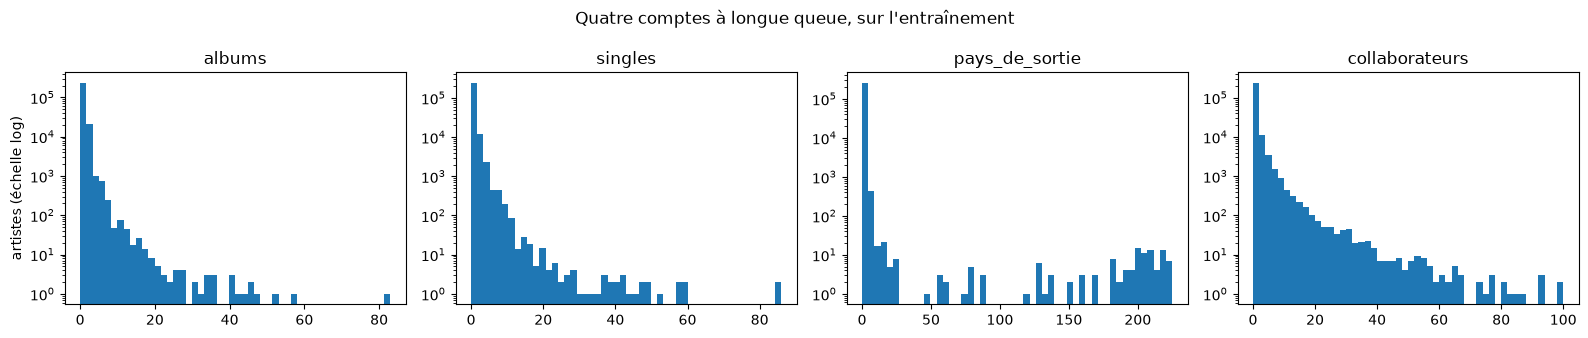

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, colonne in zip(axes, ["albums", "singles", "pays_de_sortie", "collaborateurs"]):
    entrainement[colonne].plot.hist(bins=50, log=True, ax=ax, title=colonne)
    ax.set_ylabel("")
axes[0].set_ylabel("artistes (échelle log)")
fig.suptitle("Quatre comptes à longue queue, sur l'entraînement")
plt.tight_layout()
plt.show()

Les comptes ont de longues queues, avec un maximum très loin du 99e centile (83 albums contre 3, 86 singles contre 4). 2021 va plus loin encore, avec 427 albums et 466 singles. Les quatre variables de proximité sont nulles pour plus de 99 % des artistes.

In [7]:
cas = [("albums", "max"), ("singles", "max"), ("tendance", "max"), ("tendance", "min"),
       ("pays_de_sortie", "max"), ("collaborateurs", "max"), ("delai_median", "min")]
lignes = []
for colonne, sens in cas:
    i = table[colonne].idxmax() if sens == "max" else table[colonne].idxmin()
    lignes.append({"variable": colonne, "valeur": table.loc[i, colonne], "t0": table.loc[i, "t0"],
                   "artiste": table.loc[i, "name"], "gid": table.loc[i, "gid"]})
pd.DataFrame(lignes)

,variable,valeur,t0,artiste,gid
0,albums,427.0,2021,sonnov,5fde3528-8641-4578-a031-37748a7c20ca
1,singles,466.0,2021,Sloth,10a7f4c7-71dc-4939-ad63-710dd4d8e989
2,tendance,348.0,2021,Sloth,10a7f4c7-71dc-4939-ad63-710dd4d8e989
3,tendance,-59.0,2016,Tim Timebomb,a805d7eb-fae5-4888-8660-304a8451c624
4,pays_de_sortie,229.0,2021,Tekashi 6ix9ine,2282c539-05a2-477c-82b7-fe40798d37f3
5,collaborateurs,433.0,2021,Agathocles,4a2e0104-e6ea-42ec-9399-1f670418c134
6,delai_median,-12.0,2021,Michael Hoppé,be07f590-62b1-4bfa-9802-44bb53de0b97


Vérifiés sur musicbrainz.org, ces extrêmes sont presque tous de vraies données.

- sonnov, musicien ambient russe, a 430 albums datés de 2019 et 2020 sur le site (427 dans la table).
- Sloth, projet de harsh noise, a 107 singles en 2019 et 359 en 2020, soit les 466 de la table.
- Tim Timebomb a sorti une série de singles en 2013 et plus rien en 2015, d'où une tendance de -59.
- Tekashi 6ix9ine a des singles listés pays par pays, comme GOOBA et ses 222 pays.
- Agathocles, groupe belge de grindcore, partage 426 de ses 565 disques avec d'autres groupes, d'où 433 collaborateurs.
- Michael Hoppé a un délai de -12 ans. Sa sortie Afterglow, datée de 2020 sur le site, aurait été ajoutée 12 ans avant de sortir. Sa date a donc été changée après coup. C'est la seule vraie erreur.

L'âge extrême du notebook 03 était celui de Ramon Llull, né en 1232 et crédité sur des sorties récentes. L'âge n'est plus dans la table.

In [8]:
LOG = ["albums", "eps", "singles", "disques_avant", "anciennete", "annees_actives", "editions_par_disque",
       "labels", "collaborateurs", "collaborateurs_major", "lies", "lies_major"]
BORNEES = ["tendance", "delai_median"]

bornes = entrainement[BORNEES].quantile([0.01, 0.99])
apres = pd.concat([np.log1p(entrainement[LOG]), entrainement[BORNEES].clip(bornes.loc[0.01], bornes.loc[0.99], axis=1)], axis=1)
print(bornes)
pd.DataFrame({"asymétrie avant": entrainement[LOG + BORNEES].skew(), "après": apres.skew()}).round(2)

      tendance  delai_median
0.01      -3.0          -1.0
0.99       2.0           2.0


,asymétrie avant,après
albums,13.63,0.10
eps,4.32,1.54
singles,16.66,2.35
disques_avant,10.50,1.29
anciennete,2.65,0.71
annees_actives,3.16,1.18
editions_par_disque,5.72,3.76
labels,2.19,-0.19
collaborateurs,15.02,3.20
collaborateurs_major,29.74,9.64


Les arbres n'ont besoin d'aucune transformation, seul l'ordre des valeurs compte. Une régression logistique, elle, souffre des queues. Deux options. Passer les comptes au log(1 + x) et borner tendance et delai_median aux centiles 1 et 99 de l'entraînement. Ou ramener chaque variable à ses rangs (QuantileTransformer). Le log fait tomber l'asymétrie d'albums de 13,63 à 0,10. Il ne corrige pas les variables presque toujours nulles, comme collaborateurs_major (9,64) et lies_major (9,97). Le notebook 05 prend les rangs.

In [9]:
pd.Series({
    "label_tremplin manquant = aucun label": (table["label_tremplin"].isna() == (table["labels"] == 0)).mean(),
    "part_collaborateurs_major manquant = aucun collaborateur": (table["part_collaborateurs_major"].isna() == (table["collaborateurs"] == 0)).mean(),
    "taux_pays manquant = pays manquant": (table["taux_pays"].isna() == (table["pays_manquant"] == 1)).mean(),
    "type manquant = type_manquant": (table["type"].isna() == (table["type_manquant"] == 1)).mean(),
}, name="part des lignes concordantes")

label_tremplin manquant = aucun label                       1.0
part_collaborateurs_major manquant = aucun collaborateur    1.0
taux_pays manquant = pays manquant                          1.0
type manquant = type_manquant                               1.0
Name: part des lignes concordantes, dtype: float64

Chaque valeur manquante a une seule cause, déjà portée par une autre variable.

- label_tremplin manque quand l'artiste n'a aucun label (29,92 % des lignes d'entraînement).
- part_collaborateurs_major manque quand il n'a aucun collaborateur (83,68 %).
- taux_pays manque quand le pays manque (19,81 %).

Les arbres les gardent manquantes. Une régression logistique les remplit, l'information reste dans labels, collaborateurs et pays_manquant.

## 3. Redondances

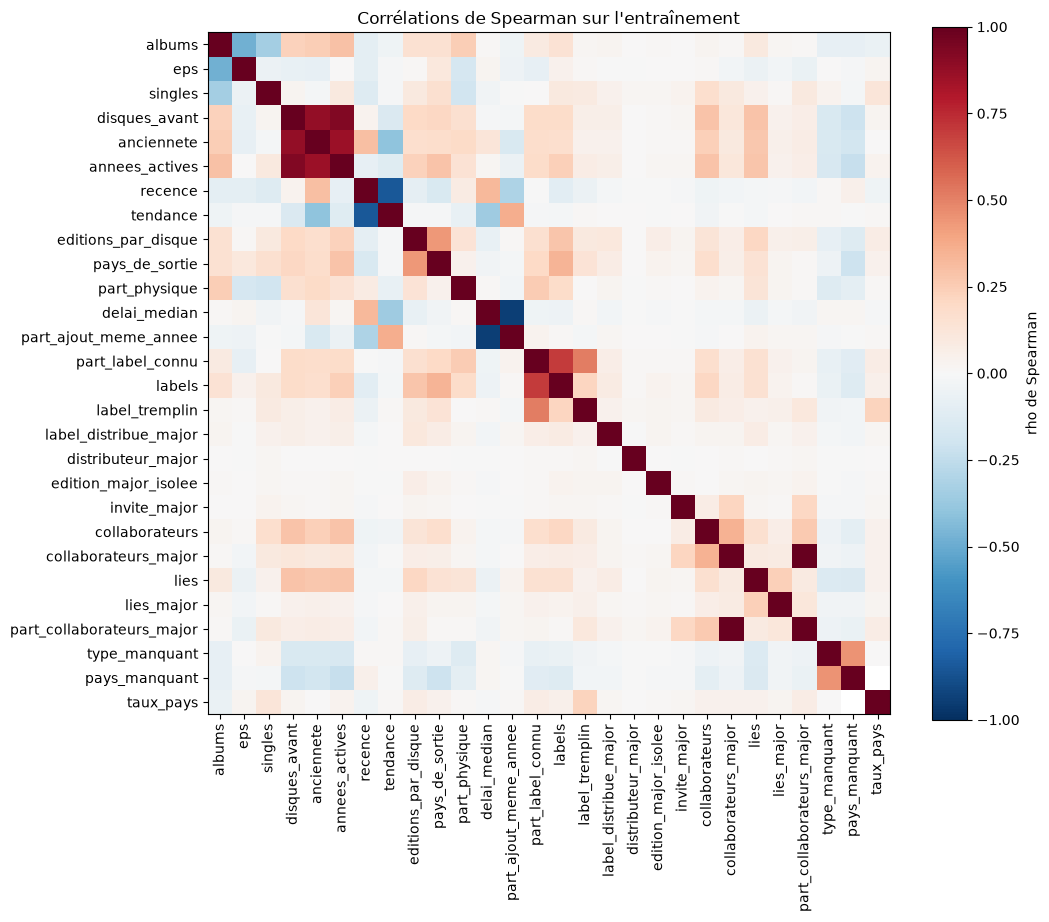

collaborateurs_major  part_collaborateurs_major    0.995
delai_median          part_ajout_meme_annee       -0.941
disques_avant         annees_actives               0.925
                      anciennete                   0.881
anciennete            annees_actives               0.856
recence               tendance                    -0.850
part_label_connu      labels                       0.696
                      label_tremplin               0.509
albums                eps                         -0.478
type_manquant         pays_manquant                0.448
dtype: float64

In [10]:
rho = entrainement[numeriques].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(rho, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(rho)), rho.columns, rotation=90)
ax.set_yticks(range(len(rho)), rho.columns)
fig.colorbar(image, label="rho de Spearman")
ax.set_title("Corrélations de Spearman sur l'entraînement")
plt.show()

paires = rho.where(np.triu(np.ones(rho.shape, dtype=bool), 1)).stack()
paires.loc[paires.abs().sort_values(ascending=False).index].head(10).round(3)

In [11]:
pd.Series({
    "singles, annees_actives": rho.loc["singles", "annees_actives"],
    "collaborateurs, collaborateurs_major": rho.loc["collaborateurs", "collaborateurs_major"],
    "collaborateurs, part_collaborateurs_major": rho.loc["collaborateurs", "part_collaborateurs_major"],
    "collaborateurs_major, part_collaborateurs_major remplie par 0":
        entrainement["collaborateurs_major"].corr(entrainement["part_collaborateurs_major"].fillna(0), method="spearman"),
}, name="rho").round(3)

singles, annees_actives                                          0.099
collaborateurs, collaborateurs_major                             0.348
collaborateurs, part_collaborateurs_major                        0.262
collaborateurs_major, part_collaborateurs_major remplie par 0    1.000
Name: rho, dtype: float64

In [12]:
signal = {colonne: auc(entrainement[colonne], entrainement["y"]) for colonne in numeriques}
signal["part_collaborateurs_major"] = auc(entrainement["part_collaborateurs_major"].fillna(0), entrainement["y"])

redondantes = paires[paires.abs() >= 0.8].reset_index()
redondantes.columns = ["variable 1", "variable 2", "rho"]
redondantes["AUC 1"] = redondantes["variable 1"].map(signal)
redondantes["AUC 2"] = redondantes["variable 2"].map(signal)
redondantes.round(3)

,variable 1,variable 2,rho,AUC 1,AUC 2
0,disques_avant,anciennete,0.881,0.529,0.497
1,disques_avant,annees_actives,0.925,0.529,0.566
2,anciennete,annees_actives,0.856,0.497,0.566
3,recence,tendance,-0.850,0.410,0.539
4,delai_median,part_ajout_meme_annee,-0.941,0.464,0.517
5,collaborateurs_major,part_collaborateurs_major,0.995,0.533,0.533


En valeur absolue, les corrélations sautent de 0,850 à 0,696, et six paires dépassent 0,8. Une fois ses manquants remplis par 0, part_collaborateurs_major est même identique à collaborateurs_major (rho 1,000). Le notebook 05 garde quand même les 30 variables, les deux variables d'une paire s'y partageront l'importance par permutation.

singles et annees_actives (0,099), collaborateurs et collaborateurs_major (0,348), collaborateurs et part_collaborateurs_major (0,262) ne sont pas redondants.

## 4. Dérive de 2014 à 2021

Moyenne de chaque variable par cohorte. La dérive, c'est l'AUC de la variable pour séparer 2021 de l'entraînement (0,5 si les deux distributions sont les mêmes).

In [13]:
derive = table.groupby("t0")[numeriques].mean().T
derive["dérive 2021"] = [auc(table[colonne], table["t0"] == 2021) for colonne in numeriques]
derive.round(3)

t0,2014,2015,2016,2017,2018,2021,dérive 2021
albums,0.847,0.846,0.831,0.827,0.820,0.838,0.480
eps,0.295,0.297,0.310,0.321,0.331,0.364,0.508
singles,0.289,0.303,0.324,0.345,0.390,0.672,0.558
disques_avant,1.498,1.640,1.678,1.677,1.802,2.268,0.539
anciennete,5.015,5.240,5.278,5.318,5.524,6.130,0.531
annees_actives,2.321,2.409,2.430,2.439,2.525,2.841,0.546
recence,2.020,2.049,2.020,2.004,2.000,1.914,0.465
tendance,-0.193,-0.240,-0.195,-0.173,-0.176,-0.102,0.520
editions_par_disque,1.083,1.095,1.110,1.113,1.111,1.102,0.502
pays_de_sortie,1.079,1.066,1.099,1.162,1.198,4.286,0.528


In [14]:
manquantes = variables[table[variables].isna().any()]
table[manquantes].isna().groupby(table["t0"]).mean().T.mul(100).round(1)

t0,2014,2015,2016,2017,2018,2021
label_tremplin,25.7,30.3,31.6,30.6,30.4,29.7
part_collaborateurs_major,84.9,84.8,84.3,83.4,81.8,76.8
type,7.1,6.4,7.3,9.2,10.7,10.3
pays,18.4,19.5,21.2,20.2,19.5,19.9
taux_pays,18.4,19.5,21.2,20.2,19.5,19.9


Deux variables dérivent nettement, à plus de 0,1 de 0,5, label_tremplin (0,638) et part_physique (0,387). Les autres restent entre 0,465 et 0,558, taux_pays compris (0,500). Les singles et les collaborateurs augmentent quand même, de 0,390 singles en moyenne en 2018 à 0,672 en 2021. La moyenne de pays_de_sortie passe de 1,198 à 4,286.

In [15]:
tranches = pd.cut(table["pays_de_sortie"], [-1, 0, 1, 2, 3, 10, 100, np.inf],
                  labels=["0", "1", "2", "3", "4 à 10", "11 à 100", "plus de 100"])
pd.crosstab(table["t0"], tranches.rename("pays de sortie"), normalize="index").mul(100).round(2)

pays de sortie,0,1,2,3,4 à 10,11 à 100,plus de 100
t0,,,,,,,
2014,9.87,79.90,8.46,1.27,0.45,0.02,0.02
2015,12.92,76.39,8.83,1.33,0.48,0.03,0.03
2016,11.90,76.10,9.93,1.49,0.52,0.03,0.03
2017,8.87,78.40,10.51,1.63,0.52,0.02,0.05
2018,7.13,80.06,10.59,1.64,0.51,0.02,0.05
2021,6.60,78.92,10.95,1.31,0.43,0.33,1.46


In [16]:
par_tranche = entrainement.groupby(tranches[table["t0"] < 2021], observed=True)["y"]
pd.DataFrame({"artistes": par_tranche.size(), "% de positifs": 100 * par_tranche.mean()}).round(2)

,artistes,% de positifs
pays_de_sortie,,
0,25676,0.80
1,201632,0.94
2,25209,1.71
3,3845,2.81
4 à 10,1283,4.44
11 à 100,62,19.35
plus de 100,100,14.00


In [17]:
pays_sorties = lire("release_country", ["release", "country", "date_year"])
par_sortie = pays_sorties.groupby("release").agg(pays=("country", "size"), annee=("date_year", "min"))
par_sortie[par_sortie["pays"] > 100].groupby("annee").size().loc[2011:2020].rename("sorties listées dans plus de 100 pays")

annee
2011     580
2012     707
2013     983
2014    1334
2015    1363
2016    1602
2017    2183
2018    2719
2019    3733
2020    5710
Name: sorties listées dans plus de 100 pays, dtype: int64

La hausse de pays_de_sortie vient de la queue. La tranche de 4 à 10 pays reste stable, 0,51 % des artistes en 2018 et 0,43 % en 2021. Mais 1,46 % des artistes de 2021 ont une sortie dans plus de 100 pays, contre 0,05 % au plus avant. Les sorties listées dans plus de 100 pays passent de 983 en 2013 à 5 710 en 2020. À l'entraînement pourtant, ce groupe passe bien plus souvent en major, ce n'est pas du bruit. On a 19,35 % de positifs entre 11 et 100 pays et 14,0 % au-delà, contre 0,94 % avec un seul pays.

Ces pays ne sont pas datables. `release_country` n'a ni id ni date. Et changer les pays d'une sortie ne touche pas à sa date de mise à jour. Comme le sexe et l'âge, pays_de_sortie est une valeur d'aujourd'hui. Une partie de son signal peut donc venir de pays ajoutés après T0, et le dump ne permet pas de le vérifier.

In [18]:
plus_de_10 = (table["pays_de_sortie"] > 10).rename("plus de 10 pays")
recentes = table["t0"].isin([2018, 2021])
groupes = table[recentes].groupby(["t0", plus_de_10[recentes]])
profil_listes = groupes[["singles", "collaborateurs", "collaborateurs_major", "labels", "part_label_connu", "part_physique"]].mean()
profil_listes.insert(0, "artistes", groupes.size())
profil_listes.round(2)

artistes  singles  collaborateurs  collaborateurs_major  \
t0   plus de 10 pays                                                            
2018 False               61433     0.39            0.54                  0.05   
     True                   47     1.85            2.23                  0.17   
2021 False               80894     0.64            0.78                  0.08   
     True                 1478     2.23            1.99                  0.41   

                      labels  part_label_connu  part_physique  
t0   plus de 10 pays                                           
2018 False              0.81              0.54           0.31  
     True               1.91              0.72           0.25  
2021 False              0.85              0.54           0.22  
     True               1.50              0.71           0.08

Les artistes à plus de 10 pays sont 1 478 en 2021 et 47 en 2018. En 2021, ils ont en moyenne 2,23 singles contre 0,64 pour les autres, et 0,41 collaborateur déjà en major contre 0,08. Ils ont donc aussi les valeurs hautes des variables les plus liées à la cible. La cohorte 2018 en compte trop peu pour dire en validation comment un modèle les classe.

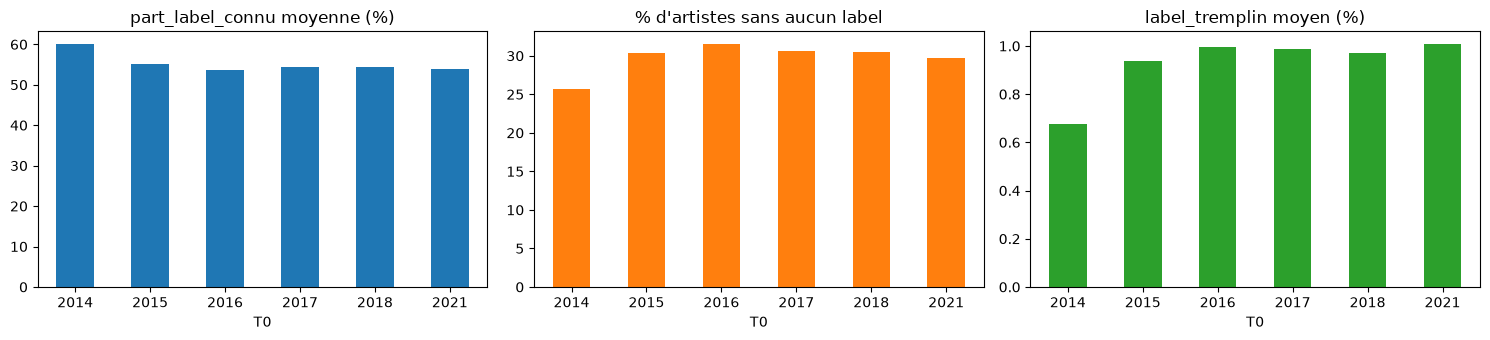

,part_label_connu moyenne (%),% d'artistes sans aucun label,label_tremplin moyen (%)
t0,,,
2014,60.21,25.69,0.68
2015,55.15,30.30,0.94
2016,53.56,31.59,0.99
2017,54.41,30.62,0.99
2018,54.36,30.43,0.97
2021,53.89,29.66,1.01


In [19]:
labels_par_cohorte = pd.DataFrame({
    "part_label_connu moyenne (%)": 100 * table.groupby("t0")["part_label_connu"].mean(),
    "% d'artistes sans aucun label": 100 * table["label_tremplin"].isna().groupby(table["t0"]).mean(),
    "label_tremplin moyen (%)": 100 * table.groupby("t0")["label_tremplin"].mean(),
})
labels_par_cohorte.plot.bar(subplots=True, layout=(1, 3), figsize=(15, 3.5), legend=False, rot=0,
                            title=list(labels_par_cohorte.columns), xlabel="T0")
plt.tight_layout()
plt.show()
labels_par_cohorte.round(2)

In [20]:
correction = {}
for colonne in ["label_tremplin", "taux_pays", "part_physique"]:
    rapport = table[colonne] / table.groupby("t0")[colonne].transform("mean")
    correction[colonne] = {
        "dérive brute": auc(table[colonne], table["t0"] == 2021),
        "dérive du rapport à la moyenne de la cohorte": auc(rapport, table["t0"] == 2021),
        "AUC brute": auc(entrainement[colonne], entrainement["y"]),
        "AUC du rapport": auc(rapport[table["t0"] < 2021], entrainement["y"]),
    }
pd.DataFrame(correction).T.round(3)

,dérive brute,dérive du rapport à la moyenne de la cohorte,AUC brute,AUC du rapport
label_tremplin,0.638,0.438,0.602,0.606
taux_pays,0.500,0.551,0.533,0.534
part_physique,0.387,0.436,0.480,0.483


Les labels se raréfient peu d'une cohorte à l'autre. part_label_connu baisse surtout entre 2014 et 2015 (60 % puis 55 %) et reste ensuite vers 54 %. La part d'artistes sans aucun label passe de 25,7 % à 29,7 %. label_tremplin, lui, monte de 0,68 % en 2014 à 1,01 % en 2021, alors que le taux de positifs baisse (partie 1). C'est un taux de passage en major de cohortes passées, vues de T0. Or vue de 2014, la base ignorait que plus de la moitié des sorties récentes en major l'étaient (notebook 03, partie 9). Rapporté à la moyenne de sa cohorte, il dérive moins (0,438) et garde son signal (AUC 0,606 contre 0,602). taux_pays ne dérive pas (0,500), le rapport le ferait dériver (0,551). Le rapport ne corrige pas part_physique (0,436). La part de sorties physiques baisse vraiment, de 0,58 en 2014 à 0,21 en 2021.

Le lien de chaque variable avec la cible, cohorte par cohorte, sur l'entraînement seulement.

In [21]:
lien = pd.DataFrame({t: {colonne: auc(g[colonne], g["y"]) for colonne in numeriques} for t, g in entrainement.groupby("t0")})
lien["écart max"] = lien.max(axis=1) - lien.min(axis=1)
lien.round(3)

,2014,2015,2016,2017,2018,écart max
albums,0.467,0.477,0.477,0.484,0.487,0.020
eps,0.511,0.531,0.542,0.537,0.525,0.031
singles,0.623,0.634,0.625,0.596,0.601,0.037
disques_avant,0.528,0.518,0.544,0.531,0.527,0.025
anciennete,0.493,0.487,0.522,0.483,0.501,0.039
annees_actives,0.568,0.558,0.581,0.560,0.565,0.023
recence,0.393,0.405,0.430,0.404,0.415,0.037
tendance,0.576,0.524,0.496,0.553,0.549,0.080
editions_par_disque,0.549,0.559,0.564,0.567,0.561,0.018
pays_de_sortie,0.528,0.558,0.582,0.587,0.557,0.058


In [22]:
cohorte_2016 = entrainement.loc[entrainement["t0"] == 2016, ["y", "singles", "part_physique", "taux_pays", "label_tremplin"]].reset_index(drop=True)
hasard = np.random.default_rng(0)
tirages = [cohorte_2016.iloc[hasard.integers(0, len(cohorte_2016), len(cohorte_2016))].reset_index(drop=True) for _ in range(100)]
pd.Series({colonne: np.std([auc(t[colonne], t["y"]) for t in tirages]) for colonne in cohorte_2016.columns.drop("y")},
          name="écart-type de l'AUC sur 100 tirages avec remise de 2016").round(3)

singles           0.011
part_physique     0.010
taux_pays         0.013
label_tremplin    0.014
Name: écart-type de l'AUC sur 100 tirages avec remise de 2016, dtype: float64

label_tremplin garde le même lien avec la cible d'une cohorte à l'autre (AUC de 0,597 à 0,627), comme taux_pays (0,528 à 0,541). singles s'affaiblit (0,623 en 2014, 0,601 en 2018), et part_physique change de sens (0,429 puis 0,507). Un modèle entraîné sur 2014 et 2015 utilise donc part_physique à contresens en 2018. Pour une cohorte, le hasard fait varier l'AUC de 0,010 à 0,014 (écart-type par tirage avec remise). Le changement de part_physique (0,078) est donc net, la baisse de singles (0,022) reste à la limite.

## 5. Pour la modélisation

On garde pays_de_sortie tel quel. On lira à part, en 2021, les 1 478 artistes à plus de 10 pays. La validation de 2018 n'en a que 47. Les modèles gardent les 30 variables, part_physique comprise. Aucune n'est rapportée à la moyenne de sa cohorte, l'AUC de label_tremplin ne passerait que de 0,602 à 0,606.

## Sources

- La table release_country, sans id ni date, https://github.com/metabrainz/musicbrainz-server/blob/1bedfed82b794a23ced029d397da01f2bd4d4256/admin/sql/CreateTables.sql#L3403-L3409
- Changer les pays d'une sortie ne touche pas sa date de mise à jour, https://github.com/metabrainz/musicbrainz-server/blob/1bedfed82b794a23ced029d397da01f2bd4d4256/lib/MusicBrainz/Server/Data/Release.pm#L908-L913